<a href="https://colab.research.google.com/github/anupbagale/image-processing-from-scratch/blob/main/notebooks/03_contrast_stretching.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# Contrast stretching

A low-contrast image uses only a narrow part of the 0 to 255 range. Contrast stretching maps that
narrow range linearly onto the full range:

$$s = (r - r_{min}) \cdot \frac{255}{r_{max} - r_{min}}$$

where $r$ is the input grey level and $s$ the output.

In [1]:
import numpy as np
import matplotlib.pyplot as plt
import cv2
from skimage import data

plt.rcParams["image.cmap"] = "gray"

The moon image from scikit-image is a good example of a dull, low-contrast photo.

In [2]:
image = data.moon()
print("min:", image.min(), " max:", image.max())
print("2nd and 98th percentile:", np.percentile(image, [2, 98]))

min: 0  max: 255
2nd and 98th percentile: [ 78. 129.]


## Min-max stretching

The formula above, using the smallest and largest pixel value:

In [3]:
def contrast_stretching(image):
    r_min, r_max = float(image.min()), float(image.max())
    if r_max == r_min:            # flat image, nothing to stretch
        return image.copy()
    stretched = (image.astype(float) - r_min) * 255.0 / (r_max - r_min)
    return stretched.astype(np.uint8)


minmax = contrast_stretching(image)
print("image changed:", not np.array_equal(minmax, image))

image changed: False


Nothing changed. Although most of the moon image lies between about 78 and 129, a few pixels are
exactly 0 and a few are 255, so the minimum and maximum already span the full range. Min-max
stretching only works when there are no such outliers.

## Percentile stretching

A more robust version ignores the darkest and brightest few percent of pixels. Here $r_{min}$ and
$r_{max}$ are replaced by the 2nd and 98th percentiles, and values outside that range are clipped.

In [4]:
def percentile_stretching(image, low=2, high=98):
    r_min, r_max = np.percentile(image, [low, high])
    stretched = (image.astype(float) - r_min) * 255.0 / (r_max - r_min)
    return np.clip(stretched, 0, 255).astype(np.uint8)


stretched = percentile_stretching(image)

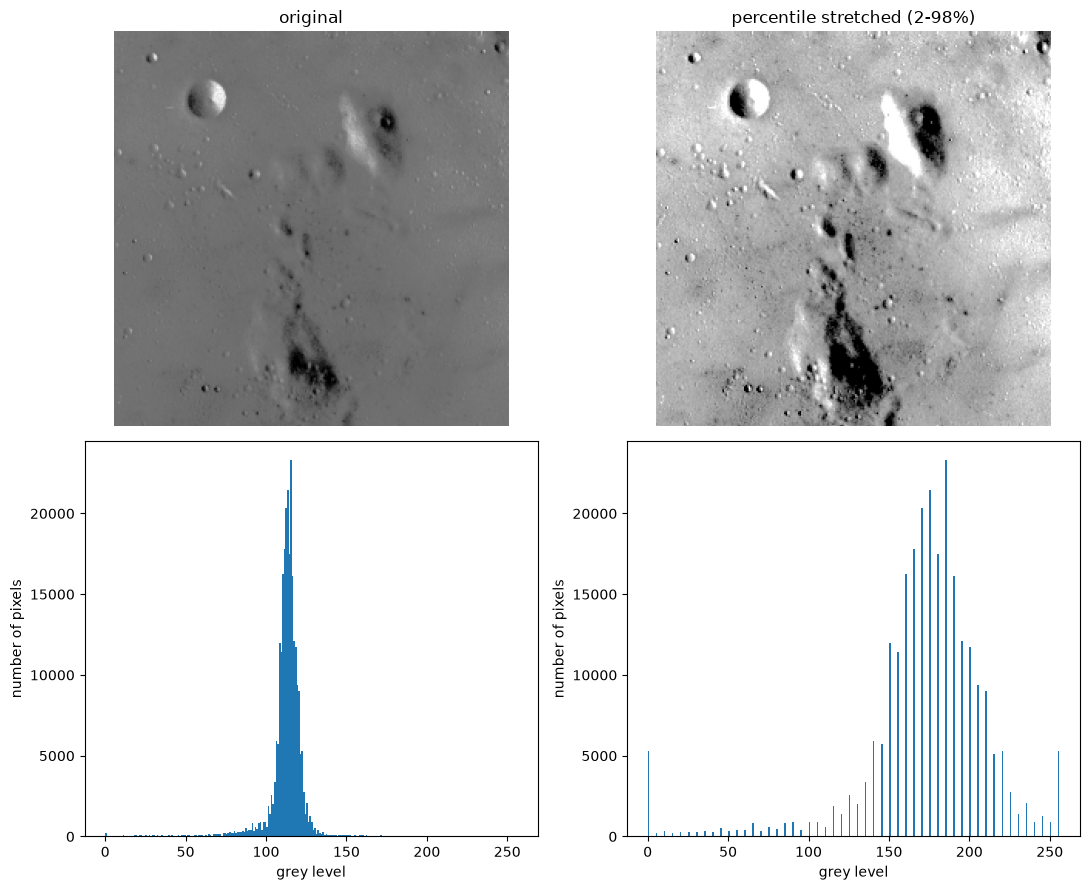

In [5]:
fig, ax = plt.subplots(2, 2, figsize=(11, 9))
ax[0, 0].imshow(image, vmin=0, vmax=255); ax[0, 0].set_title("original")
ax[0, 1].imshow(stretched, vmin=0, vmax=255); ax[0, 1].set_title("percentile stretched (2-98%)")
for a in ax[0]:
    a.axis("off")

ax[1, 0].hist(image.ravel(), bins=256, range=(0, 256))
ax[1, 1].hist(stretched.ravel(), bins=256, range=(0, 256))
for a in ax[1]:
    a.set_xlabel("grey level")
    a.set_ylabel("number of pixels")
plt.tight_layout()
plt.show()

The histogram of the stretched image covers the whole range, and details on the surface are much
easier to see. The gaps between the bars are expected. Stretching cannot create new grey levels,
it only moves the existing ones further apart. Clipping also merges everything outside the 2-98%
range into 0 and 255, so the stretched image ends up with fewer distinct levels than before:

In [6]:
print("different grey levels in the original:", len(np.unique(image)))
print("different grey levels after stretching:", len(np.unique(stretched)))

different grey levels in the original: 178
different grey levels after stretching: 52


## Comparison with scikit-image

`skimage.exposure.rescale_intensity` does the same linear mapping.

In [7]:
from skimage import exposure

p2, p98 = np.percentile(image, [2, 98])
reference = exposure.rescale_intensity(image, in_range=(p2, p98), out_range=(0, 255)).astype(np.uint8)
diff = np.abs(stretched.astype(int) - reference.astype(int))
print("largest difference:", diff.max(), "grey level")

largest difference: 0 grey level
